In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.datasets import load_iris
# Load the dataset
iris = load_iris()

# Convert to a Pandas DataFrame for easier handling in Jupyter
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

# Display the first few rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df['species'].value_counts()
#counting the species number 

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [4]:
df.shape

(150, 5)

In [5]:
df.isnull().sum()
# checking null values

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

# There is no any null value

In [6]:
df.duplicated().sum()
# checking duplicate values

np.int64(1)

In [7]:
df[df.duplicated()]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
142,5.8,2.7,5.1,1.9,virginica


# There is one duplicate value so removing duplicate

In [8]:
df=df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.info()
# information about the data i.e Dtype etc

<class 'pandas.core.frame.DataFrame'>
Index: 149 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  149 non-null    float64
 1   sepal width (cm)   149 non-null    float64
 2   petal length (cm)  149 non-null    float64
 3   petal width (cm)   149 non-null    float64
 4   species            149 non-null    object 
dtypes: float64(4), object(1)
memory usage: 7.0+ KB


In [11]:
df.describe()
# checking statistical value of numeric columns

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


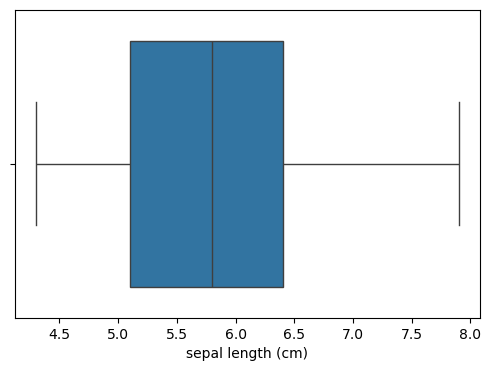

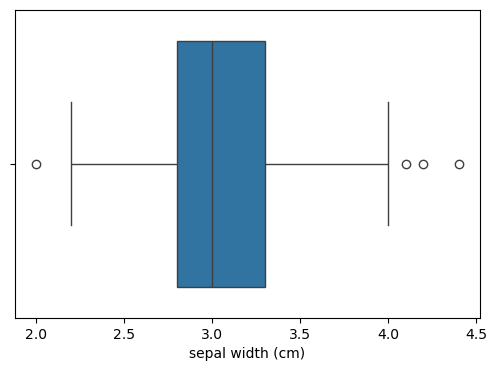

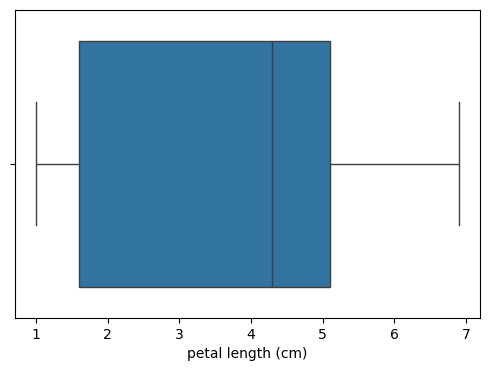

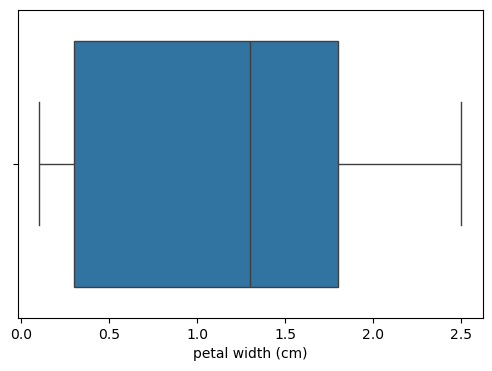

In [12]:
numeric_column=['sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)']
for col in numeric_column:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

# checking if any outliers contains in the numerical columns

In [13]:
df['sepal width (cm)'].value_counts()

sepal width (cm)
3.0    26
2.8    14
3.2    13
3.4    12
3.1    11
2.9    10
2.7     8
2.5     8
3.3     6
3.5     6
3.8     6
2.6     5
3.6     4
2.3     4
3.7     3
2.2     3
2.4     3
3.9     2
4.4     1
4.2     1
4.1     1
4.0     1
2.0     1
Name: count, dtype: int64

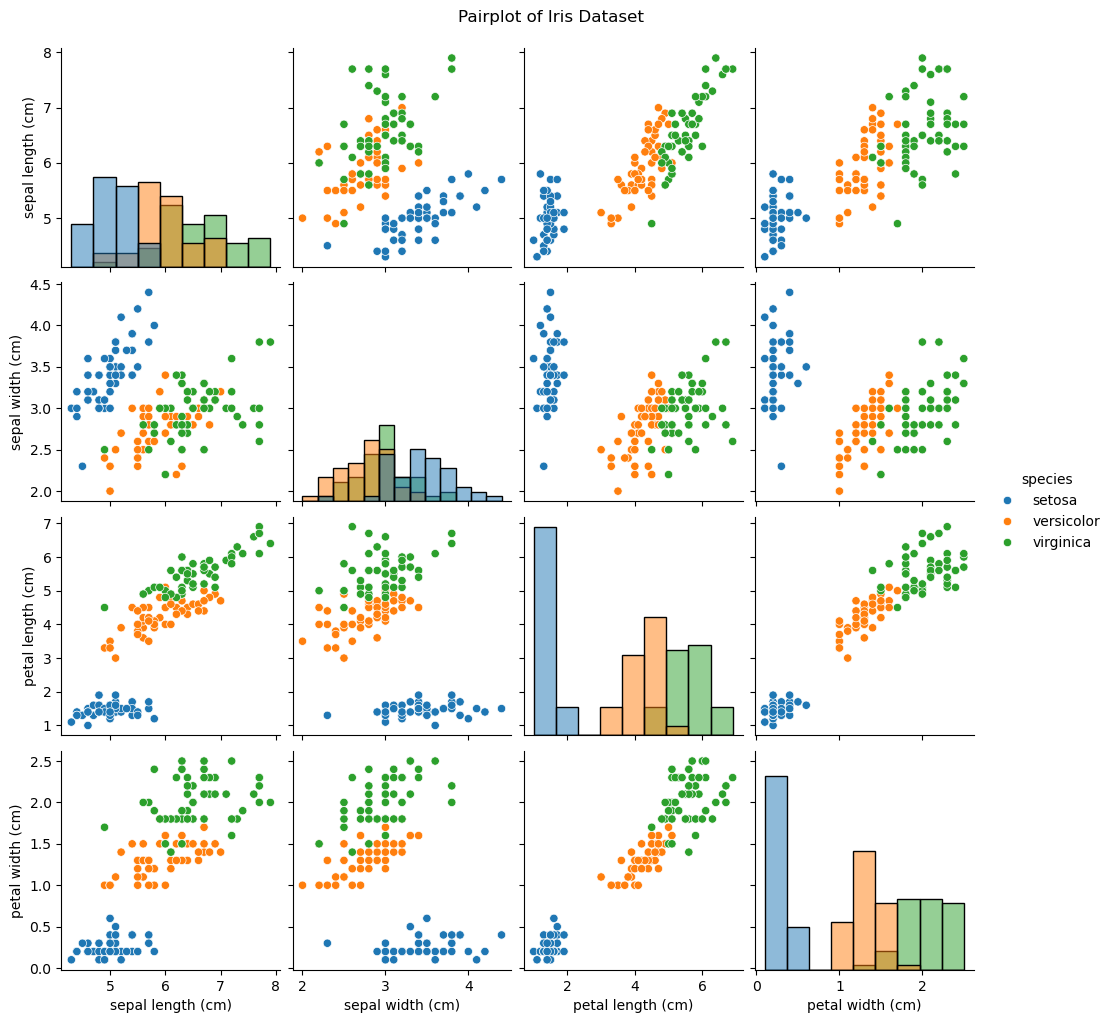

In [14]:
sns.pairplot(
    df,
    hue='species',
    diag_kind='hist'
)

plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()
# shows the relationship between every pair of numerical features and displays their distributions

# result of pairplot
## sepal length vs sepal width shows weak relation
## petal length vs petal width shows strong relation

<Axes: >

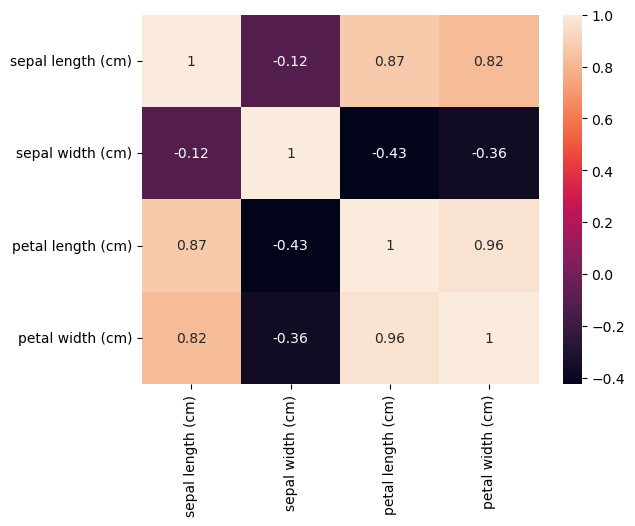

In [15]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
#statistical technique used to measure the strength and direction of the relationship between two numerical variables

In [16]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [17]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [18]:
X=df.drop('species',axis=1)
y=df['species']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
scaler=StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
le=LabelEncoder()
y=le.fit_transform(y)

In [22]:
from sklearn.metrics import accuracy_score, f1_score, classification_report,confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [23]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [24]:
y_predict=model.predict(X_test)

In [25]:
accuracy_score(y_test,y_predict)

1.0

In [26]:
confusion_matrix(y_test,y_predict)

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])

In [27]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [28]:
model = KNeighborsClassifier()

model.fit(X_train, y_train)

KNeighborsClassifier()

In [29]:
y_predict=model.predict(X_test)

In [30]:
accuracy_score(y_test,y_predict)

1.0

In [31]:
confusion_matrix(y_test,y_predict)

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])

In [32]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# Here due to the limited dataset the accuracy